This is an alternative to running the baysian optimisation. This is a standard parameter exploration which exploits all CPUs available on the machine. 

In [1]:
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
%cd ..
from model_variations import *
from parameters import *

sim_path = 'simulation_results/'


model_list = [ulR_ulY, ulR_lY, ulR_cY, lR_ulY, lR_lY, lR_cY, cR_ulY, cR_lY, cR_cY]
f_names = ['unlimitedR_unlimitedY_rho', 'unlimitedR_limitedY_rho','unlimitedR_competitiveY_rho', 'limitedR_unlimitedY_rho','limitedR_limitedY_rho','limitedR_competitiveY_rho','competitiveR_unlimitedY_rho','competitiveR_limitedY_rho','competitiveR_competitiveY_rho']
Rs_comps = [[0.5,1.0],[0.5,1.0],[0.5,1.0],[200,400],[200,400],[200,400],[50,100],[50,100],[50,100]]

def slope_calc(α_h, β_h , model, Rs_here): 
    
    R1, R2 = Rs_here

 
    #prepare parameter dictionary
    parameters = dict()
    
    parameters['α'] = α_h
    parameters['β'] = β_h/l_samples
    
    parameters['γ'] = γ #γ_h
    parameters['l'] = l_samples
    parameters['Y_max'] = N
    parameters['N'] = N


    x0 = np.ones([N])*x_init
    init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 
    
    parameters['R'] = R1
    y1 = simulation_wrapper(init_state,parameters,model, sim_time, dt, [True, sampling])[-1, 2,:]
    

    parameters['R'] = R2
    y2 = simulation_wrapper(init_state,parameters,model,sim_time, dt, [True, sampling])[-1, 2,:]
    
    slope_here = (np.mean(y2[long_ind] - y1[long_ind])/ np.mean(y2[short_ind] - y1[short_ind]))
    
    return slope_here

#we check the same paramter spaces for all of them
alpha_vals = np.linspace(0.001, 0.5,50)
beta_vals = np.linspace(0.001, 0.5,50)


def run_parallel(model, filename, r): 
    res = Parallel(n_jobs = -1)(delayed(slope_calc) (alpha, beta, model, r) for alpha in alpha_vals for beta in beta_vals)
    np.save(sim_path+filename+'.npy',res)





/home/patricia/Downloads/competition_in_proteinsynthesis_in_autism


In [2]:
for m_ind, m in enumerate(model_list): 
    run_parallel(m, f_names[m_ind], Rs_comps[m_ind])
    
#started Thursday at 7:20, ended saturday 9:47

In [3]:
#plot the parameter exploration results
from cmcrameri import cm
from plotting_helper import *
figures_path = 'figures/'

c_map = cm.berlin

def exploration_plot(filename, colorbar_minmax): 
    
    data = np.load('simulation_results/'+filename+'.npy')
    
    data = data.reshape([alpha_vals.shape[0], beta_vals.shape[0]])
    
    layout = '''
        AA
        AA
        '''

    fig = plt.figure(figsize=(22, 10))

    height_ratios = [1,0.2]
    width_ratios = [1,0.2]
    


    specs, gs = panel_specs(layout, fig=fig)
    gs.set_height_ratios(height_ratios)
    gs.set_width_ratios(width_ratios)
    gs.hspace=0.8
    axes = {}
    for letter in 'A':
        axes[letter] = ax = fig.add_subplot(specs[letter])
    for a in list('A'):
        axes[a].set_axis_off()


    
    ax = fig.add_subplot(gs[0,0])
    pic = ax.imshow(data, interpolation = 'none', vmin = colorbar_minmax[0], vmax = colorbar_minmax[1], cmap = c_map)
    

    cbar = fig.colorbar(pic, ax=ax, label = 'ρ')
    ax.set_xticks(np.arange(beta_vals.shape[0])[::5])
    ax.set_xticklabels(np.round(beta_vals,3)[::5])
    ax.tick_params("x", rotation=45)
    ax.set_xlabel('β')
    ax.set_yticks(np.arange(alpha_vals.shape[0])[::5])
    ax.set_yticklabels(np.round(alpha_vals,3)[::5])
    ax.set_ylabel('α')

    
         
    plt.savefig(figures_path + 'fig2_small_fig'+filename+'.pdf')
    plt.show()
    

unlimitedR_unlimitedY_rho


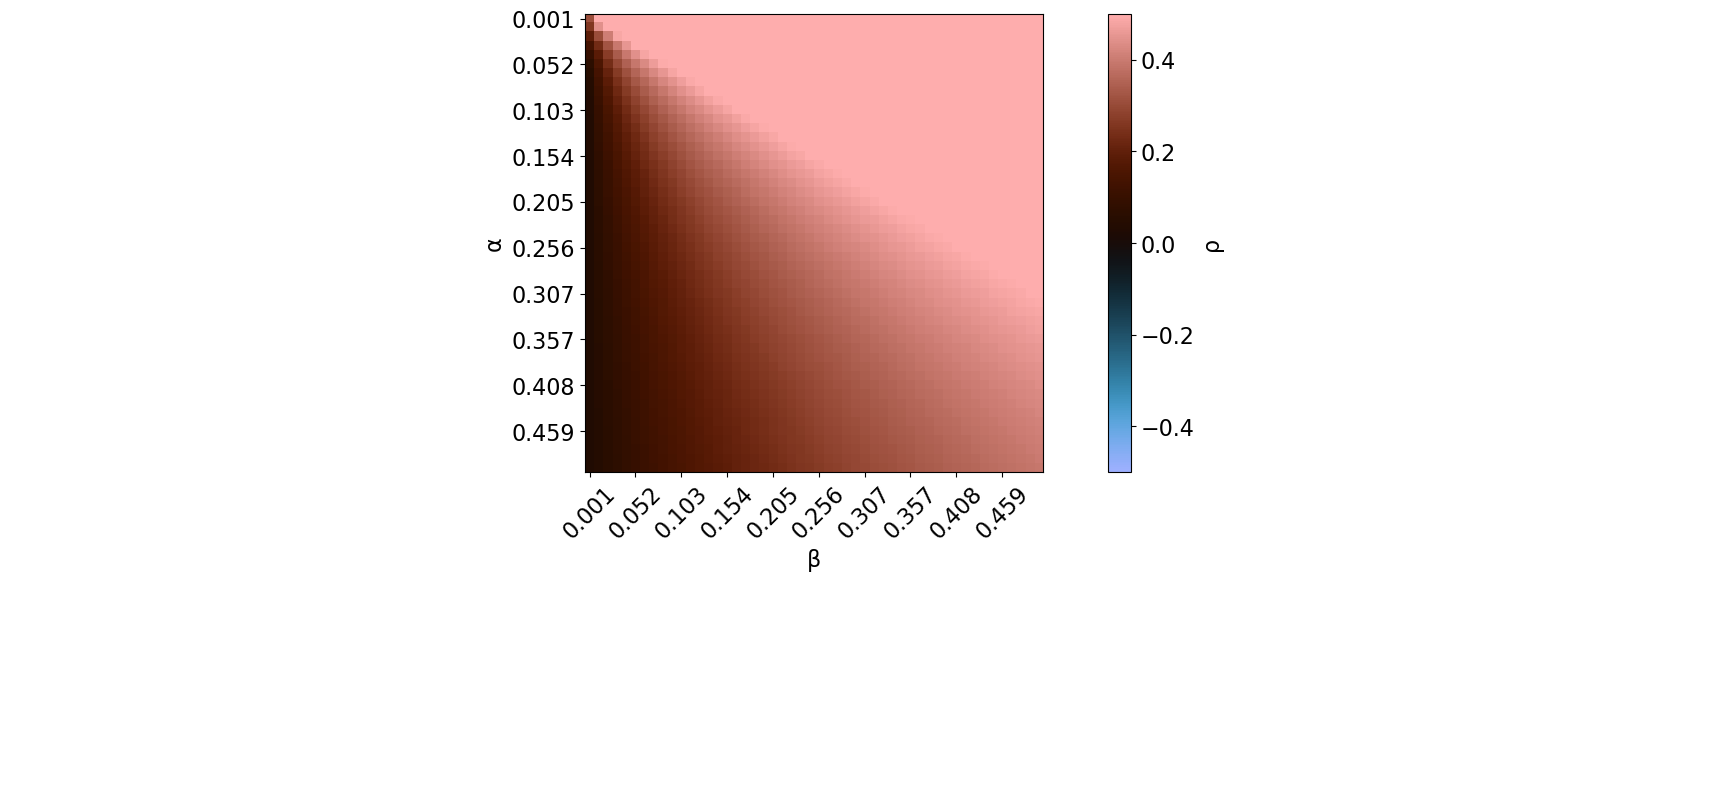

unlimitedR_limitedY_rho


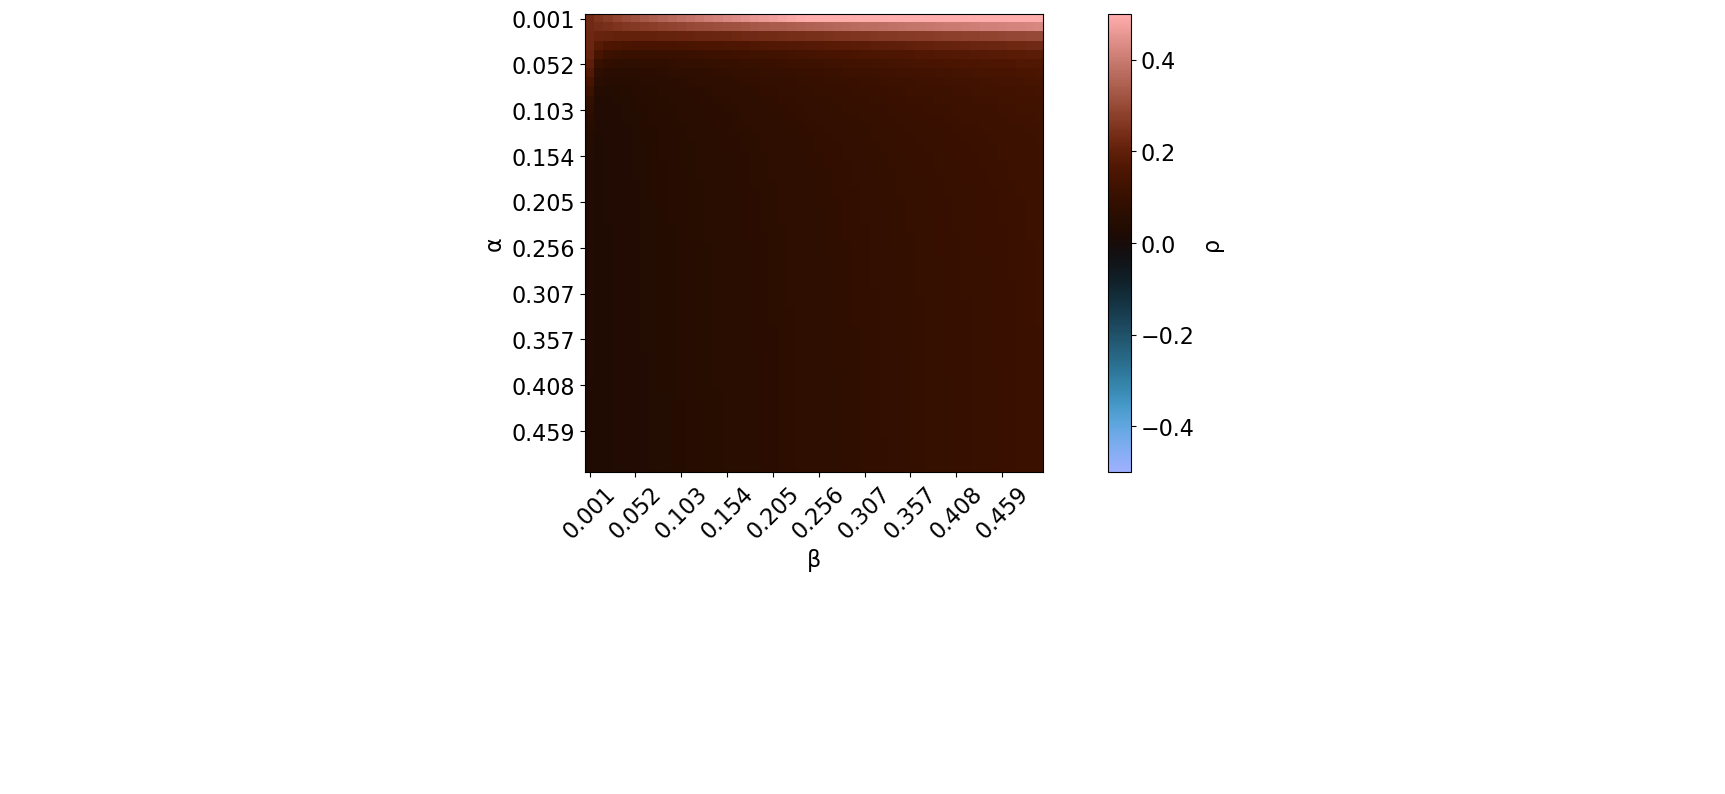

unlimitedR_competitiveY_rho


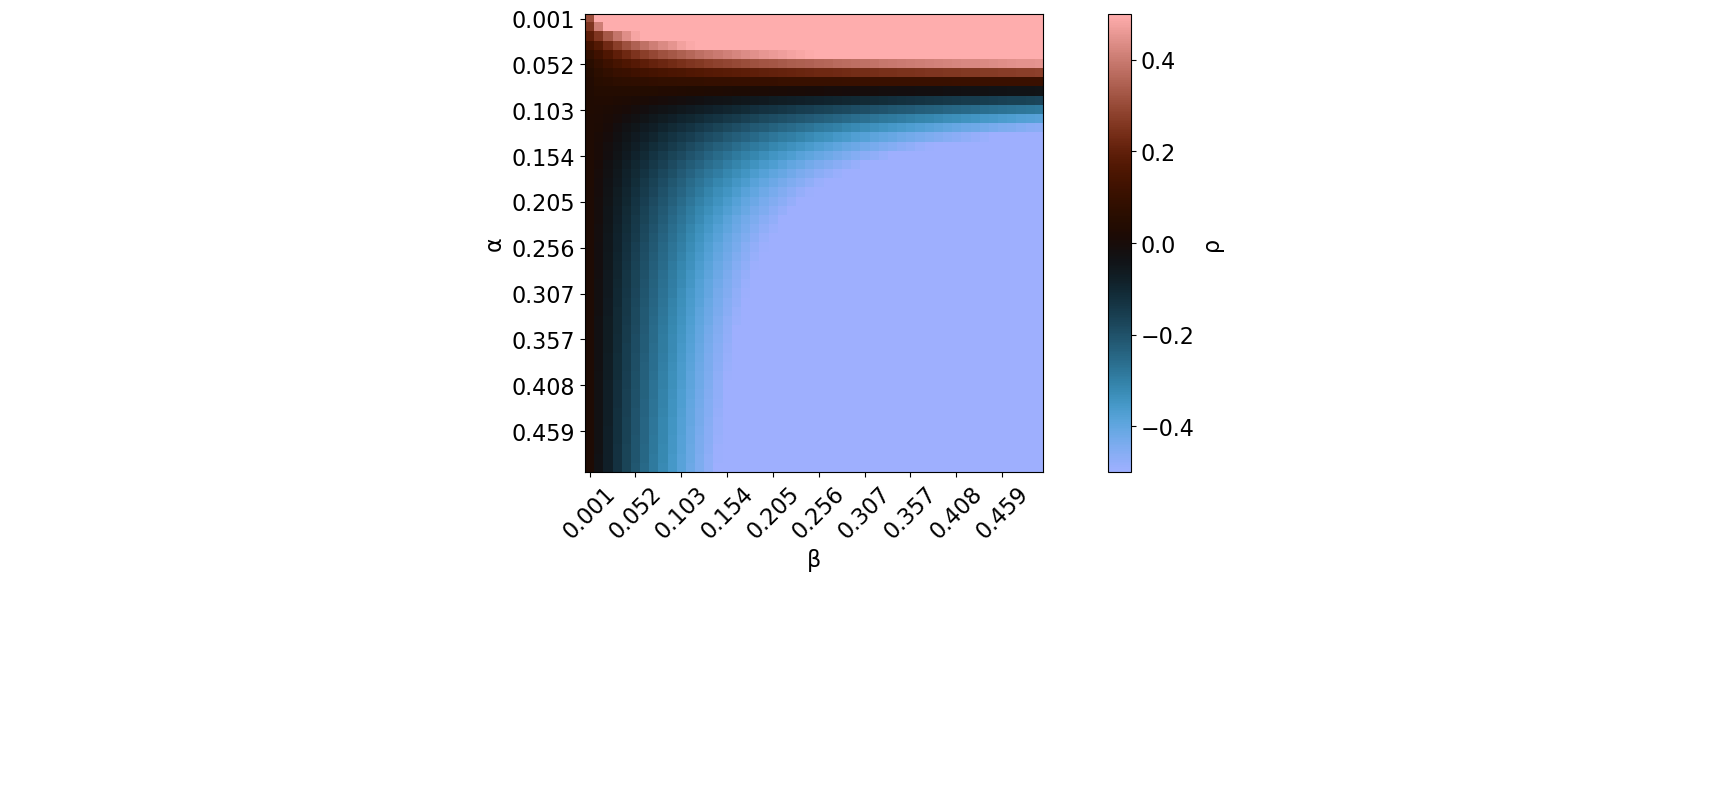

limitedR_unlimitedY_rho


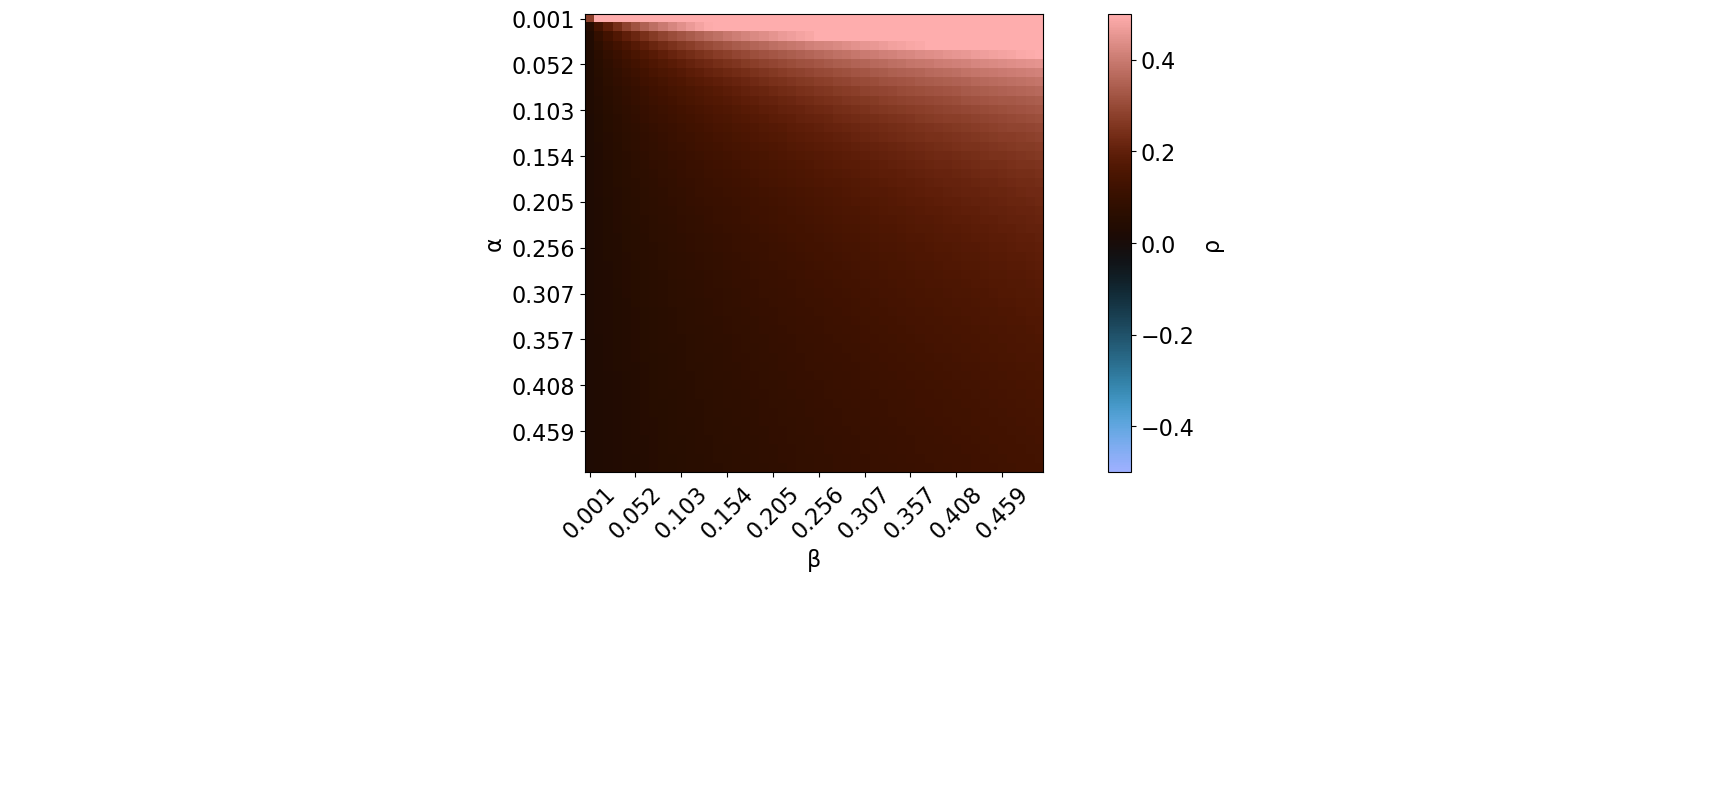

limitedR_limitedY_rho


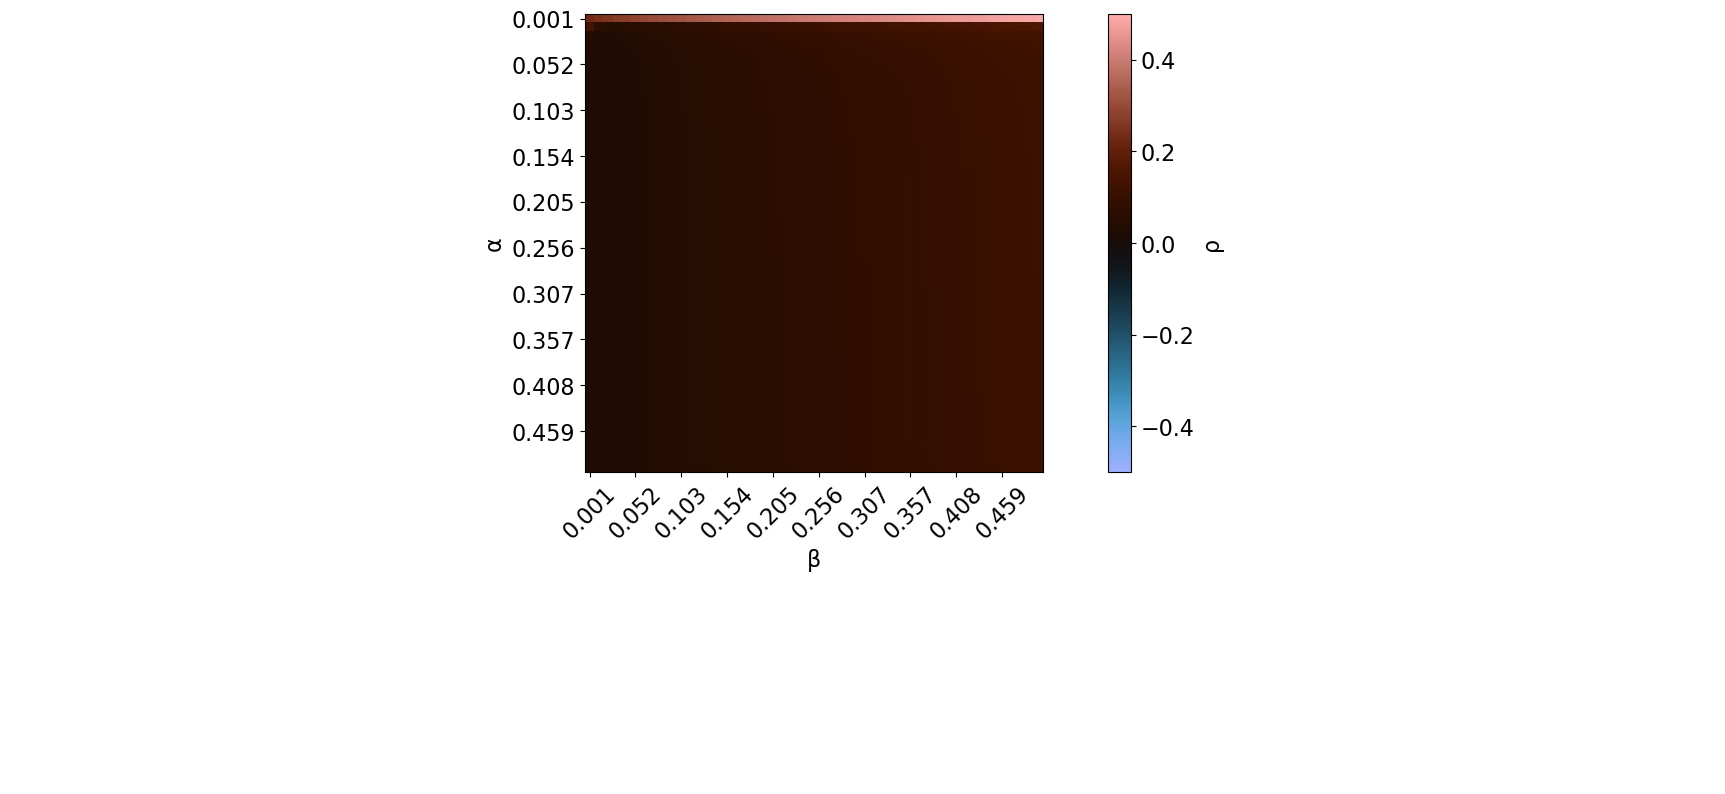

limitedR_competitiveY_rho


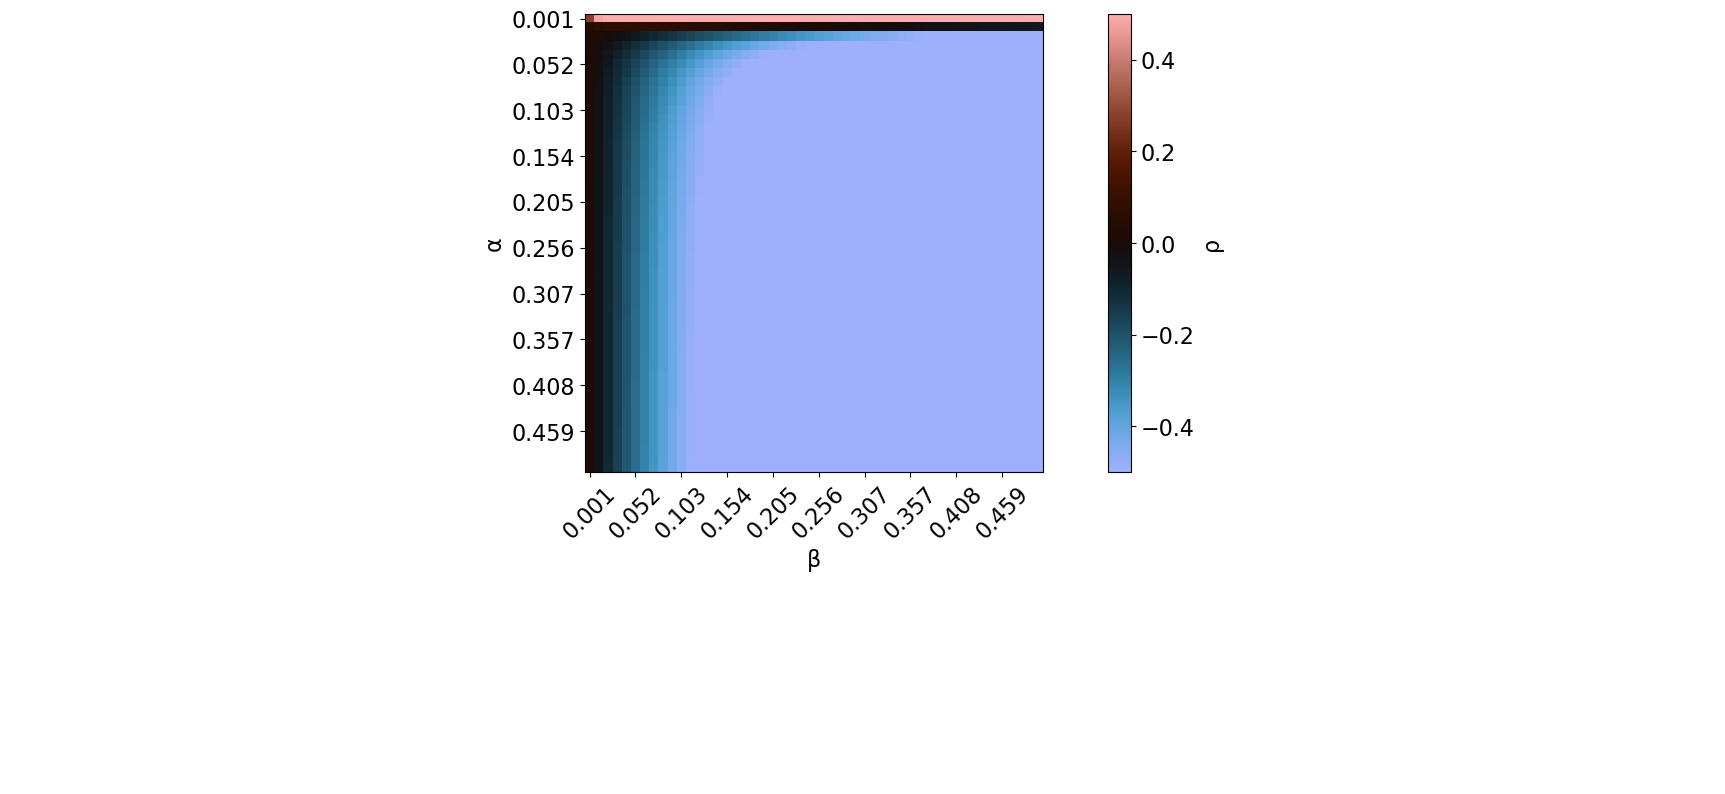

competitiveR_unlimitedY_rho


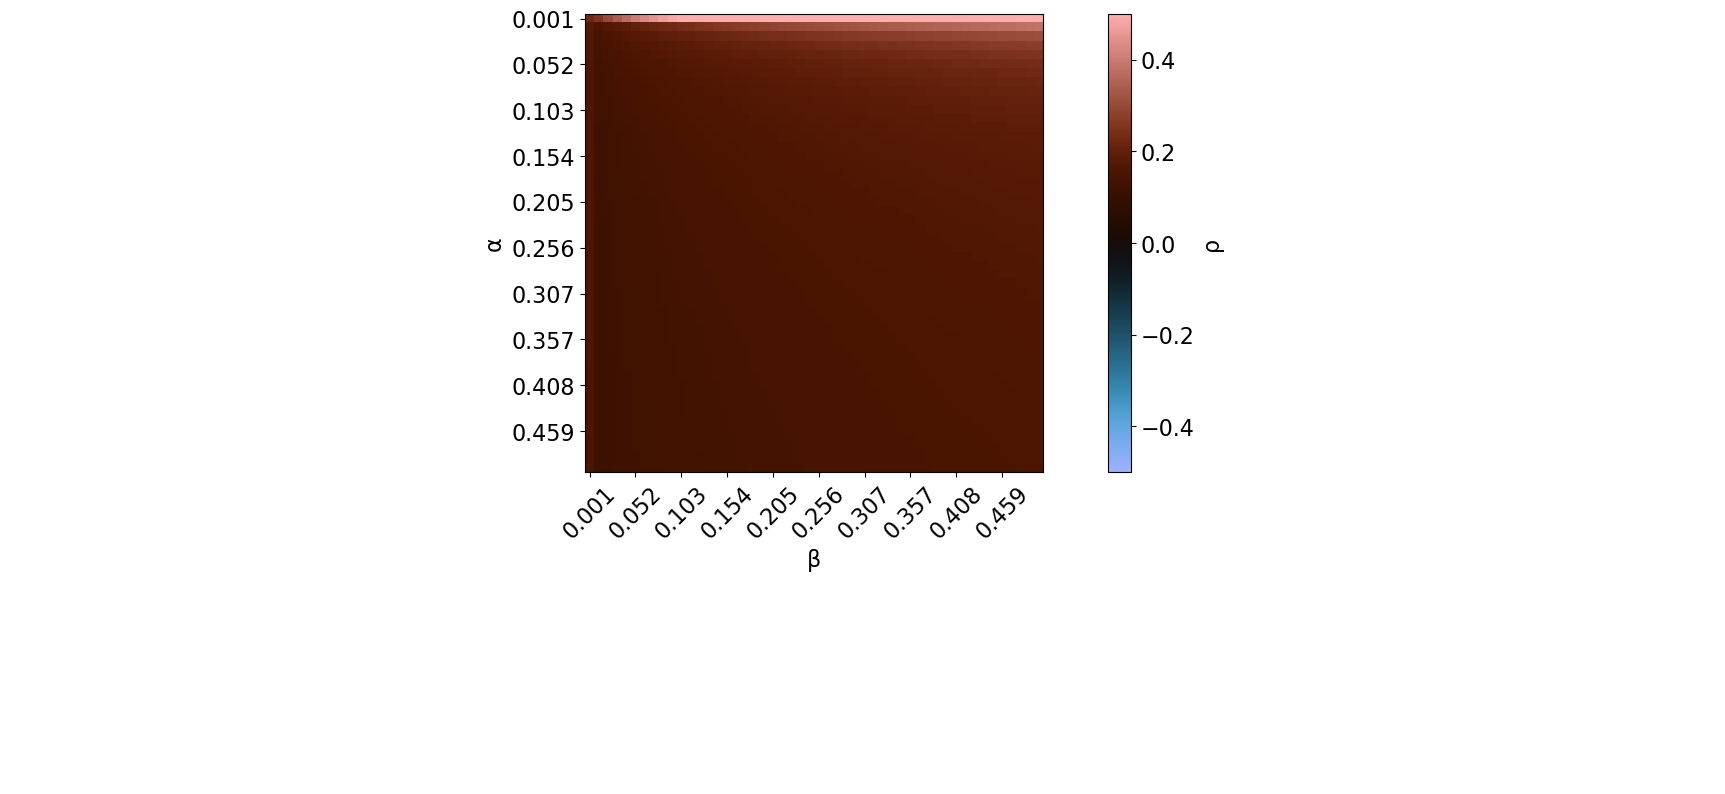

competitiveR_limitedY_rho


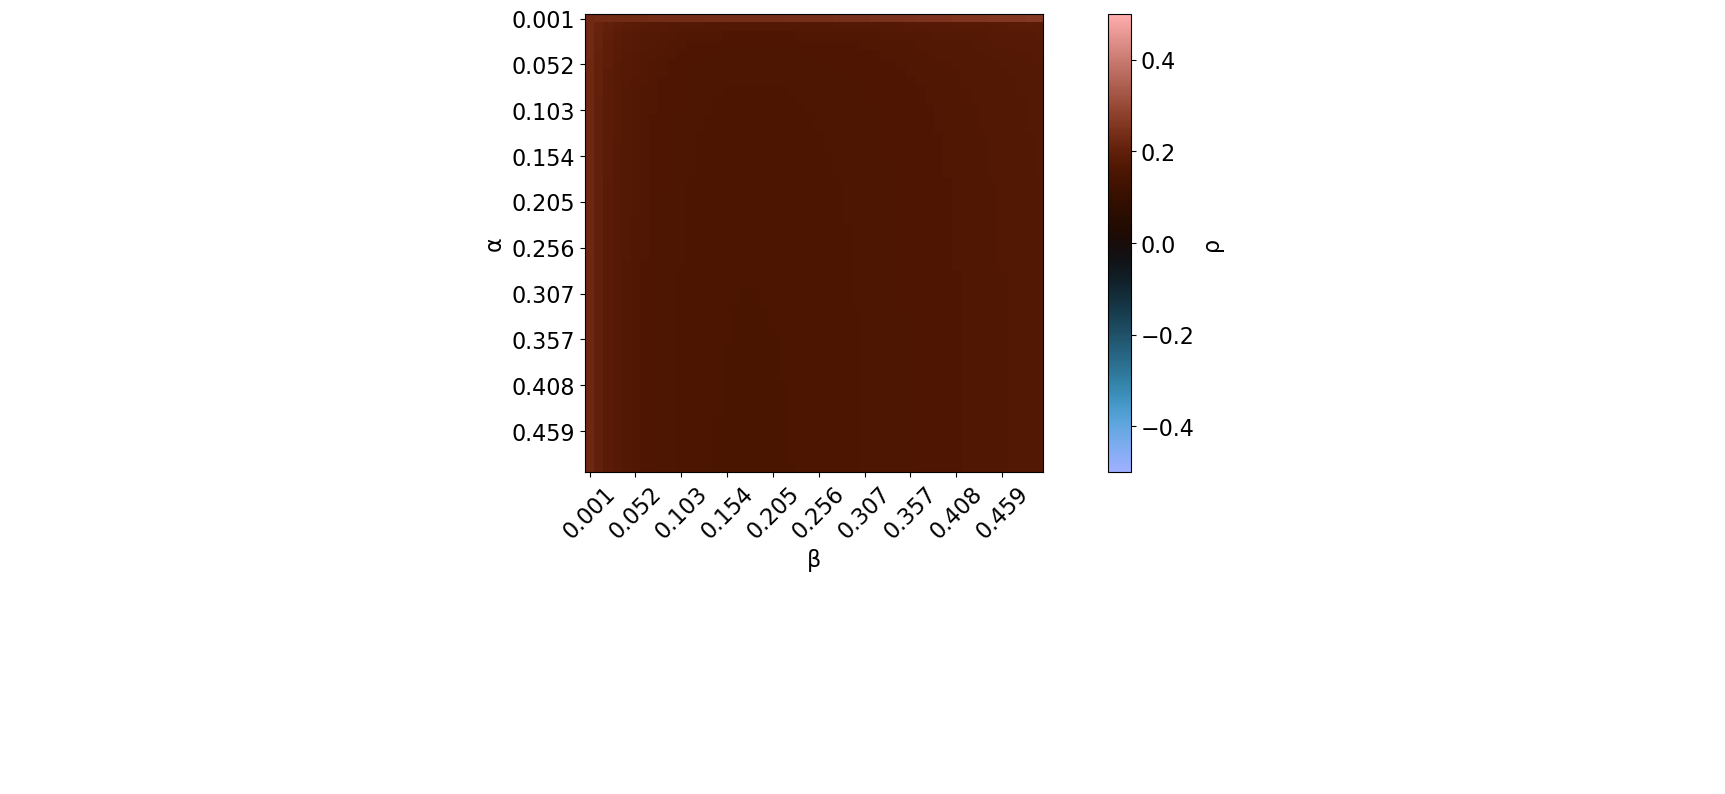

competitiveR_competitiveY_rho


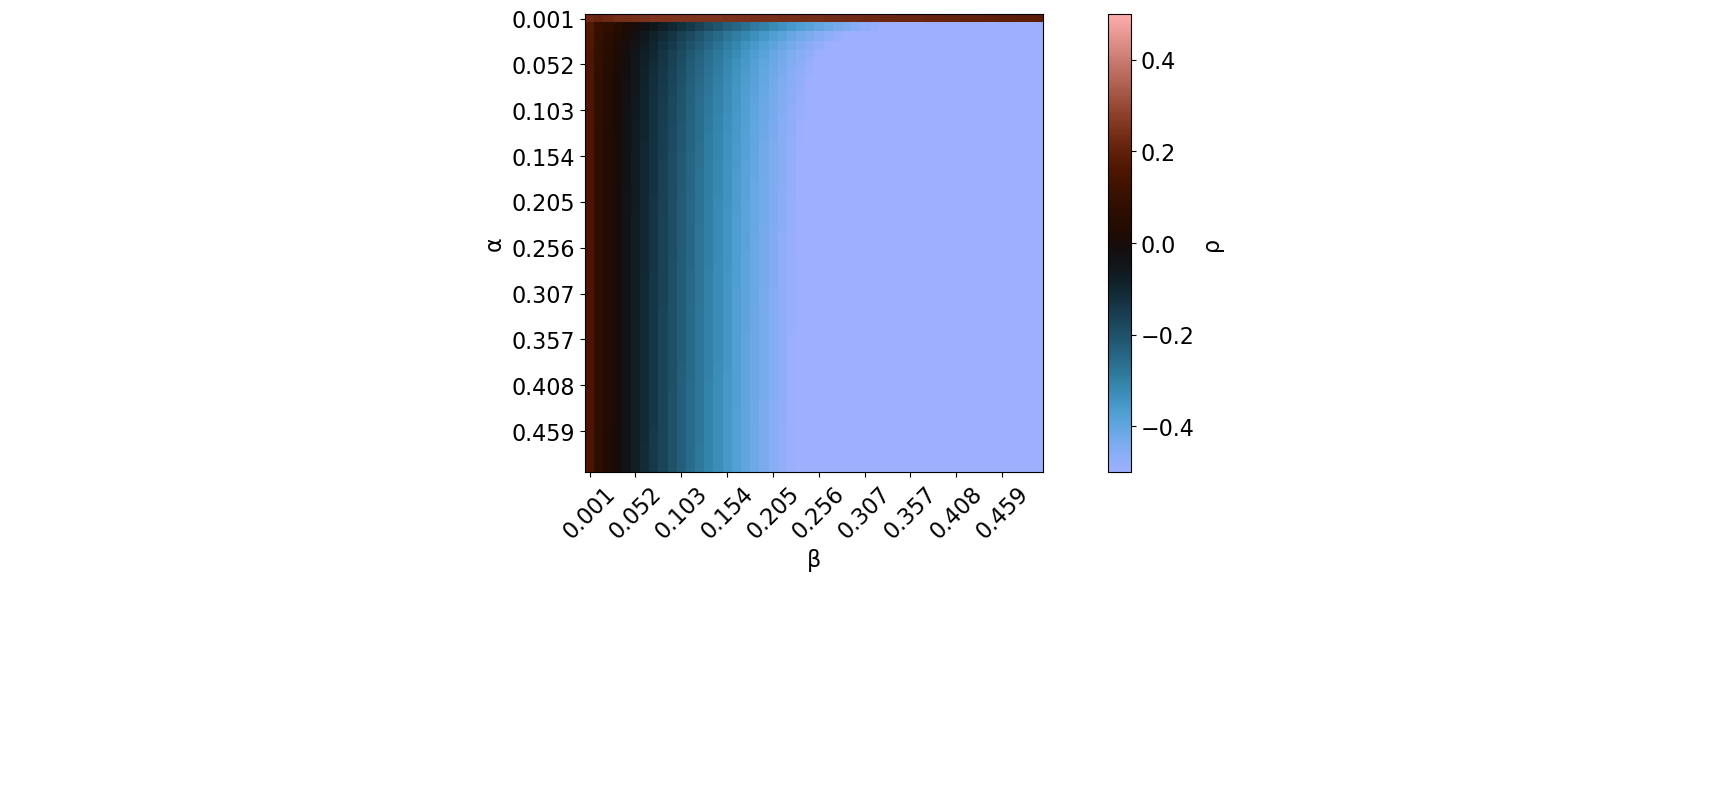

In [4]:
lims = [-0.5,0.5]

for f in f_names: 
    print(f)
    exploration_plot(f, lims)